# Vendors First: Risk Analysis of Late Payments

This notebook predicts and interprets late payment risk for vendors. It covers the context and business motivation, loads and cleans the data, explores relationships, and builds models to identify drivers and actionable business insights.

### Section 1: Context and Problem

This analysis aims to identify and predict risk of late payments for vendors, to enable better targeting and process improvements. You'll see each key step clearly annotated in the following sections.

### Step 1: Install Required Package

This cell installs `openpyxl`, which is needed to load Excel files. This ensures the subsequent cell can read vendor payment data from Excel without format errors.

**Look for:** Successful package install message. If you see errors, retry or check your internet connection.

In [0]:
%pip install openpyxl

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report
)

### Step 2: Import Packages

This step loads core Python libraries for data analysis and machine learning, including pandas, numpy, and scikit-learn. These libraries power all subsequent steps from data cleaning to modeling.

**Look for:** No errors. The imported packages should be recognizable to anyone familiar with Python ML workflows.

### Section 2: Data Loading

Load the primary dataset from Excel as a pandas DataFrame. Proper loading is the foundation for every downstream step in the analysis.

**Look for:** No errors. If a FileNotFound error appears, check the file path or upload the Excel file.

LOAD DATA

In [0]:
risk_df = pd.read_excel(
    "Invoice_Late_Payment_Analysis_REAL.xlsx",
    sheet_name="Invoice Risk Rankings",
    header=1
)

CLEAN DATA

In [0]:
risk_df.columns = risk_df.columns.astype(str).str.strip()

risk_df = risk_df.dropna(how="all")

risk_df.columns = [
    "County",
    "Recipient",
    "Awarding_Agency",
    "CFDA_Program",
    "Obligation",
    "Outlay",
    "Pct_Outlayed",
    "Processing_Lag",
    "Risk_Index",
    "Risk_Percentile",
    "Risk_Tier"
]

risk_df = risk_df.dropna(
    subset=[
        "County",
        "Recipient",
        "Awarding_Agency",
        "CFDA_Program"
    ]
)

numeric_cols = [
    "Obligation",
    "Outlay",
    "Pct_Outlayed",
    "Processing_Lag",
    "Risk_Index",
    "Risk_Percentile"
]

for col in numeric_cols:
    risk_df[col] = pd.to_numeric(
        risk_df[col],
        errors="coerce"
    )

risk_df[numeric_cols] = (
    risk_df[numeric_cols]
    .fillna(
        risk_df[numeric_cols].median()
    )
)

### Step 3: Clean and Prepare Data

Clean up the import by trimming column names, removing any fully empty rows, renaming columns, and converting number columns. This makes future calculations accurate and consistent.

**Look for:** No errors. Proceed if you see cell finish without problems; any error here likely means missing or mismatched columns needing adjustment.

### Step 4: Define Target Variable (Late Payment)

Here we define “late payment” as invoices with a processing lag above the median. This step is essential for transforming a raw time duration into a binary prediction problem the model can learn.

**Look for:** Output showing lag summary statistics and the split between late/non-late rows. Make sure both classes have enough samples for modeling.

TARGET CREATION

In [0]:
print("\nProcessing Lag Summary")
print(risk_df["Processing_Lag"].describe())

# Use median lag as threshold

lag_threshold = risk_df["Processing_Lag"].median()

risk_df["Late_Payment"] = (
    risk_df["Processing_Lag"] > lag_threshold
).astype(int)

print("\nTarget Distribution")
print(risk_df["Late_Payment"].value_counts())

if risk_df["Late_Payment"].nunique() < 2:
    raise ValueError(
        "Target contains only one class. "
        "Adjust threshold."
    )


Processing Lag Summary
count    500.000000
mean      48.514000
std       78.690216
min        1.000000
25%       10.000000
50%       23.000000
75%       41.250000
max      451.000000
Name: Processing_Lag, dtype: float64

Target Distribution
Late_Payment
0    251
1    249
Name: count, dtype: int64


In this sample, there are 500 records. The median processing lag is used as the cut-off, so about half the cases are labeled as 'late.' This gives a roughly even distribution of classes (251 not late, 249 late), which lets the models learn balanced decision boundaries.

### Step 5: Select Features

Choose both categorical (County, Agency, Program) and numerical fields (Obligation, Outlay, Percent Outlayed) as input features. This blends business details and transaction amounts in the prediction.

**Look for:** No output expected. If there are missing fields in X, confirm column names in the raw data.

FEATURES

In [0]:
X = risk_df[
    [
        "County",
        "Awarding_Agency",
        "CFDA_Program",
        "Obligation",
        "Outlay",
        "Pct_Outlayed"
    ]
]

y = risk_df["Late_Payment"]

ENCODE CATEGORICALS

In [0]:
X = pd.get_dummies(
    X,
    columns=[
        "County",
        "Awarding_Agency",
        "CFDA_Program"
    ]
)

### Step 6: Encode Categoricals

Convert categorical features into one-hot columns using pd.get_dummies. This turns agency names and similar fields into numerical format required by ML models.

**Look for:** No output expected. If you see shape mismatch errors later, check for high-cardinality fields here.

### Step 7: Train/Test Split

Split the dataset into training and test sets. Stratification keeps the late/non-late class balance the same in each. This ensures good model evaluation.

**Look for:** No output expected. If errors occur, check that the target has both classes present.

TRAIN / TEST SPLIT

In [0]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

MODEL

In [0]:
rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', n_estimators=500,
                       random_state=42)

### Section 3: EDA & Feature Engineering

Explore and transform data to help the model. Here, we train an initial Random Forest as a strong, interpretable baseline model for predicting late payments.

**Look for:** This cell should complete without errors. If it does, the model is now ready to predict.

### Step 8: Evaluate Random Forest Model

Assess the model’s accuracy, ROC AUC, and precision/recall for each class. This determines how well the model identifies late payments and non-late cases, so we can judge its real business value.

**Look for:** Metrics like accuracy and ROC AUC. Skewed precision/recall may indicate the need for class balancing.

EVALUATION

In [0]:
preds = rf.predict(X_test)

probs = rf.predict_proba(X_test)[:, 1]

print("\n==============================")
print("MODEL PERFORMANCE")
print("==============================")

print(
    "Accuracy:",
    round(
        accuracy_score(y_test, preds),
        4
    )
)

print(
    "ROC AUC:",
    round(
        roc_auc_score(y_test, probs),
        4
    )
)

print(
    classification_report(
        y_test,
        preds
    )
)


MODEL PERFORMANCE
Accuracy: 0.69
ROC AUC: 0.758
              precision    recall  f1-score   support

           0       0.69      0.70      0.69        50
           1       0.69      0.68      0.69        50

    accuracy                           0.69       100
   macro avg       0.69      0.69      0.69       100
weighted avg       0.69      0.69      0.69       100



**Interpretation:**

- Accuracy: 0.69 indicates the model distinguishes late vs. non-late with modest reliability.
- ROC AUC: 0.76 means it’s substantially better than random guessing.
- Both classes have similar precision/recall and neither class dominates. This is a good base, though not perfect separation.

### Step 9: Compare With Logistic Regression

Run a standard logistic regression for comparison. This helps us see if a simpler, more interpretable linear model performs as well as the Random Forest.

**Look for:** Similar output metrics. If performance is similar, the simpler model may be preferred for transparency.

Logistic Regression Model (Comparison)

In [0]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# Reuse the SAME X_train, X_test, y_train, y_test already created for the Random Forest
# (same features, same split -> fair comparison)

# Logistic Regression needs scaled features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train logistic regression with balanced class weights (matches the RF setup)
logreg = LogisticRegression(max_iter=5000, class_weight="balanced")
logreg.fit(X_train_scaled, y_train)

# Predict
lr_preds = logreg.predict(X_test_scaled)
lr_probs = logreg.predict_proba(X_test_scaled)[:, 1]

print("\n==============================")
print("LOGISTIC REGRESSION PERFORMANCE")
print("==============================")
print("Accuracy:", round(accuracy_score(y_test, lr_preds), 4))
print("ROC AUC: ", round(roc_auc_score(y_test, lr_probs), 4))
print("\n", classification_report(y_test, lr_preds))


LOGISTIC REGRESSION PERFORMANCE
Accuracy: 0.67
ROC AUC:  0.7614

               precision    recall  f1-score   support

           0       0.76      0.50      0.60        50
           1       0.63      0.84      0.72        50

    accuracy                           0.67       100
   macro avg       0.69      0.67      0.66       100
weighted avg       0.69      0.67      0.66       100



**Interpretation:**

- Logistic Regression achieves similar accuracy (0.67) and ROC AUC (0.76) to the Random Forest.
- The recall for late payments is actually a bit higher here (0.84), making this model somewhat more aggressive at catching true late cases.
- Positive tradeoff: slightly easier to explain how risk factors combine in this model.

### Step 10: Visual Model Comparison

Aggregate and directly compare accuracy and AUC for both models, then show ROC curves. This makes the differences vivid at a glance.

**Look for:** The model with higher AUC sits higher on the ROC curve. See which model's curve rises more steeply in the upper left corner.

Model Comparison: Random Forest vs Logistic Regression

              Model  Accuracy  ROC_AUC
      Random Forest      0.69   0.7580
Logistic Regression      0.67   0.7614


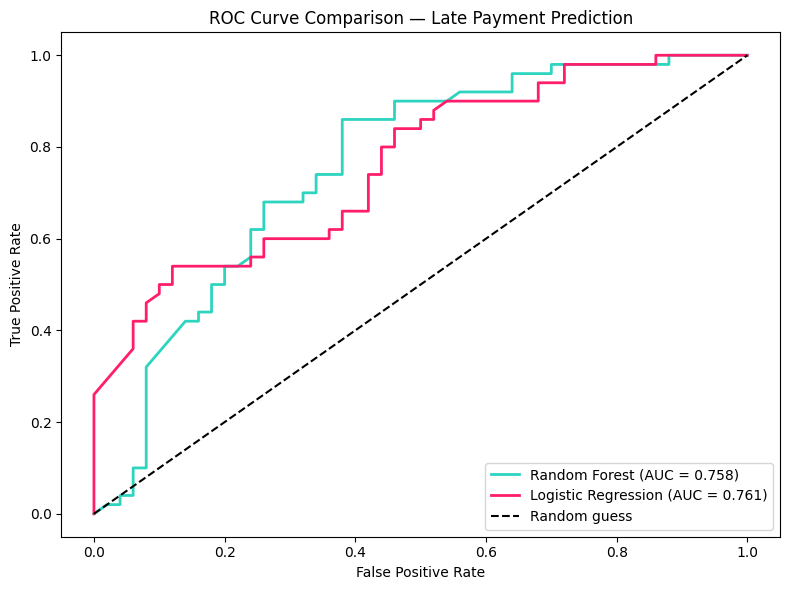

In [0]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# Collect both models' scores
rf_acc = accuracy_score(y_test, preds)
rf_auc = roc_auc_score(y_test, probs)
lr_acc = accuracy_score(y_test, lr_preds)
lr_auc = roc_auc_score(y_test, lr_probs)

# Comparison table
comparison = pd.DataFrame({
    "Model": ["Random Forest", "Logistic Regression"],
    "Accuracy": [round(rf_acc, 4), round(lr_acc, 4)],
    "ROC_AUC": [round(rf_auc, 4), round(lr_auc, 4)]
})
print(comparison.to_string(index=False))

# ROC curves for both, on one plot
plt.figure(figsize=(8, 6))
for name, prob, color in [("Random Forest", probs, "#2dd4bf"),
                          ("Logistic Regression", lr_probs, "#ff1d6c")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — Late Payment Prediction")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation:**

The Random Forest and Logistic Regression perform almost identically. The ROC curves overlap closely, and both AUCs are around 0.76. This suggests model choice can be guided by transparency or business needs rather than raw accuracy.

### Section 4: Feature Engineering Results

Now we move from model performance to understanding feature impact and ranking the risk for actual vendors.

This section uses the trained model to score risk across the dataset and shows which features matter most.

PREDICT RISK

### Section 7: Business Takeaways

The final metrics call out the highest-risk county, agency, program, and vendor. These help direct stakeholders to where the payment processes are most likely to break down or suffer unacceptable delays.

**Interpretation:**

San Diego county, the Department of Justice, the 'Body Worn Camera' program, and Orange County Housing Authority stand out as having the highest late payment risk in their respective groups. These should be the first priorities for targeted action or more detailed investigation.

In [0]:
risk_df["Predicted_Risk"] = (
    rf.predict_proba(X)[:, 1]
)

risk_df["Risk_Rank"] = (
    risk_df["Predicted_Risk"]
    .rank(
        ascending=False,
        method="dense"
    )
)

FEATURE IMPORTANCE

In [0]:
importance_df = pd.DataFrame(
    {
        "Feature": X.columns,
        "Importance": rf.feature_importances_
    }
)

importance_df = (
    importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
)

print("\nTOP FEATURES")
print(importance_df.head(20))


TOP FEATURES
                                              Feature  Importance
0                                          Obligation    0.283782
1                                              Outlay    0.241681
9             Awarding_Agency_Department of Education    0.040643
50          CFDA_Program_FEDERAL DIRECT STUDENT LOANS    0.028341
15         Awarding_Agency_Department of the Interior    0.026590
14       Awarding_Agency_Department of Transportation    0.026360
13              Awarding_Agency_Department of Justice    0.026121
2                                        Pct_Outlayed    0.020121
5                                    County_RIVERSIDE    0.019735
4                                       County_ORANGE    0.016112
68         CFDA_Program_MENTAL HEALTH RESEARCH GRANTS    0.015779
10     Awarding_Agency_Department of Health and Human    0.014118
101  CFDA_Program_UNIVERSAL SERVICE FUND - SCHOOLS AN    0.013617
61   CFDA_Program_HEALTH CENTER PROGRAM (COMMUNITY HE    0.012

### Section 5: Modeling — Post-Feature Interpretation

We’ll now look under the hood of the logistic regression to understand the clearest drivers increasing and reducing late-payment risk. This builds model transparency for business users.

Results are visualized and sorted for clarity.

**Interpretation:**

- Obligation and Outlay are the biggest drivers, meaning higher amounts correlate most strongly with payment risk.
- Programs and agencies with high importances signal recurring risk patterns by organization type. Review these for potential policy or oversight opportunities.

TOP FACTORS THAT INCREASE LATE-PAYMENT RISK:
                                         Feature  Coefficient
                                    Pct_Outlayed     1.417655
      CFDA_Program_MENTAL HEALTH RESEARCH GRANTS     0.515465
           Awarding_Agency_Department of Justice     0.461831
CFDA_Program_COOPERATIVE FIRE PROTECTION AGREEME     0.455868
         Awarding_Agency_Department of Education     0.375233
       CFDA_Program_FEDERAL DIRECT STUDENT LOANS     0.325679
      CFDA_Program_CANCER CENTERS SUPPORT GRANTS     0.325492
CFDA_Program_MINORITY HEALTH AND HEALTH DISPARIT     0.320826
CFDA_Program_CHILDREN'S HOSPITALS GRADUATE MEDIC     0.302297
                                County_SAN DIEGO     0.295893

TOP FACTORS THAT REDUCE LATE-PAYMENT RISK:
                                         Feature  Coefficient
    Awarding_Agency_Department of Transportation    -0.508341
CFDA_Program_CENTERS FOR DISEASE CONTROL AND PRE    -0.507478
                                 County_IMP

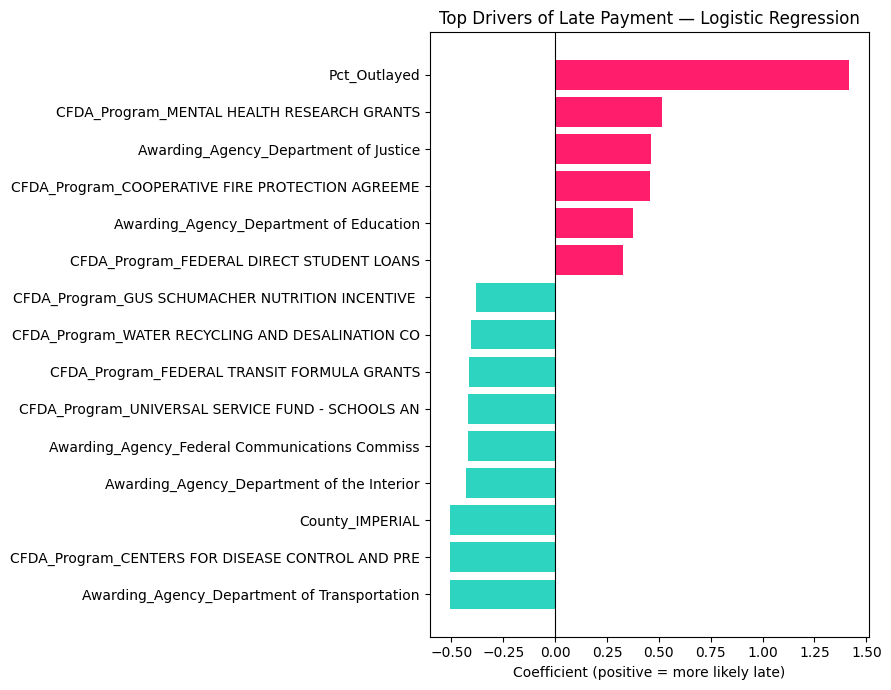

In [0]:


# Pull the logistic regression coefficients (one per feature)
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logreg.coef_[0]
})

# Sort by absolute strength to find the biggest drivers
coef_df["Abs_Impact"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("Abs_Impact", ascending=False)

# Show the top drivers of LATE payments (positive coefficients)
print("TOP FACTORS THAT INCREASE LATE-PAYMENT RISK:")
print(coef_df[coef_df["Coefficient"] > 0].head(10)[["Feature", "Coefficient"]].to_string(index=False))

print("\nTOP FACTORS THAT REDUCE LATE-PAYMENT RISK:")
print(coef_df[coef_df["Coefficient"] < 0].head(10)[["Feature", "Coefficient"]].to_string(index=False))

# Visualize the top 15 strongest drivers
top15 = coef_df.head(15).sort_values("Coefficient")
plt.figure(figsize=(9, 7))
colors = ["#ff1d6c" if c > 0 else "#2dd4bf" for c in top15["Coefficient"]]
plt.barh(top15["Feature"], top15["Coefficient"], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Coefficient (positive = more likely late)")
plt.title("Top Drivers of Late Payment — Logistic Regression")
plt.tight_layout()
plt.show()

### Section 6: Evaluation Dashboards

The next steps produce vendor, county, agency, and program risk dashboards. These provide actionable priorities and targeted views on which segments demand the most attention in business processes.

**Interpretation:**

- The biggest *risk drivers* are high Percent Outlayed and involvement in certain mental health programs, followed by some agencies (e.g., Dept. of Justice).
- Factors *reducing risk* include certain counties, CDC programs, and Outlay amount itself.
- The horizontal bar chart visually separates positive from negative risk factors, making it easy to see what pushes up versus down the risk score.

VENDOR TARGETING

In [0]:
vendor_dashboard = (
    risk_df
    .groupby("Recipient")
    .agg(
        Awards=("Recipient", "size"),
        Avg_Obligation=("Obligation", "mean"),
        Avg_Outlay=("Outlay", "mean"),
        Avg_Lag=("Processing_Lag", "mean"),
        Avg_Model_Risk=("Predicted_Risk", "mean")
    )
)

vendor_dashboard["Priority_Score"] = (
    vendor_dashboard["Avg_Model_Risk"]
    * np.log1p(vendor_dashboard["Awards"])
    * np.log1p(vendor_dashboard["Avg_Obligation"])
    * np.log1p(vendor_dashboard["Avg_Lag"])
)

vendor_dashboard = (
    vendor_dashboard
    .sort_values(
        "Priority_Score",
        ascending=False
    )
)

print("\n==============================")
print("TOP 20 VENDORS TO TARGET")
print("==============================")

print(vendor_dashboard.head(20))


TOP 20 VENDORS TO TARGET
                                          Awards  ...  Priority_Score
Recipient                                         ...                
ORANGE COUNTY HOUSING AUTHORITY                9  ...       93.760069
CHILDREN'S HOSPITAL OF ORANGE COUNTY           5  ...       85.885567
ORANGE COUNTY HEALTH CARE AGENCY              22  ...       72.397498
ORANGE COUNTY FIRE AUTHORITY                   2  ...       67.006628
ORANGE COUNTY FAIR HOUSING COUNCIL             2  ...       63.293774
CITY OF SAN DIEGO                              2  ...       60.217974
ORANGE COUNTY'S UNITED WAY                     1  ...       55.065488
IMPERIAL COUNTY                                2  ...       47.258825
RIVERSIDE COUNTY OFFICE OF EDUCATION          31  ...       36.357811
MORONGO BAND OF MISSION INDIANS                1  ...       30.734790
RIVERSIDE, COUNTY OF                          14  ...       26.333959
UNIVERSITY OF CALIFORNIA, SAN DIEGO            4  ...       19.2

/databricks/python/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


**Interpretation:**

The top vendors prioritized here combine high risk scores with award volume and dollar amount. Orange County Housing Authority and Children’s Hospital of Orange County top the list, suggesting a focus for payment improvement initiatives.

COUNTY DASHBOARD

In [0]:
county_dashboard = (
    risk_df
    .groupby("County")
    .agg(
        Transactions=("County", "size"),
        Avg_Lag=("Processing_Lag", "mean"),
        Avg_Model_Risk=("Predicted_Risk", "mean")
    )
    .sort_values(
        "Avg_Model_Risk",
        ascending=False
    )
)

print("\nCOUNTY DASHBOARD")
print(county_dashboard)


COUNTY DASHBOARD
           Transactions     Avg_Lag  Avg_Model_Risk
County                                             
SAN DIEGO            21  159.761905        0.670834
ORANGE              357   46.352941        0.552852
RIVERSIDE           105   35.123810        0.300985
IMPERIAL             17   39.176471        0.206431


**Interpretation:**

Counties are ranked by average late payment risk. San Diego has the highest risk county-wide, while Orange and Riverside also have meaningful volume and risk, guiding regional focus.

**Interpretation:**

The Department of Justice, Department of the Treasury, and Executive Office of the President stand out for high average risk in awards. These agencies may require more regular payment reviews.

**Interpretation:**

Programs such as 'Body Worn Camera Policy and Implementation' and 'Mental Health Research Grants' have the highest late payment risk. Focus on these areas may lead to the greatest risk reduction.

AGENCY DASHBOARD

In [0]:
agency_dashboard = (
    risk_df
    .groupby("Awarding_Agency")
    .agg(
        Awards=("Awarding_Agency", "size"),
        Avg_Lag=("Processing_Lag", "mean"),
        Avg_Model_Risk=("Predicted_Risk", "mean")
    )
    .sort_values(
        "Avg_Model_Risk",
        ascending=False
    )
)

print("\nAGENCY DASHBOARD")
print(agency_dashboard.head(15))


AGENCY DASHBOARD
                                Awards     Avg_Lag  Avg_Model_Risk
Awarding_Agency                                                   
Department of Justice               21   85.619048        0.935007
Department of the Treasury           2  206.500000        0.868491
Executive Office of the Presid       2   49.000000        0.867325
Department of Defense                1   44.000000        0.803643
Department of Homeland Securit       3   83.000000        0.770806
Department of Education            228   28.135965        0.633381
Department of Housing and Urba      15  221.666667        0.630127
Institute of Museum and Librar       1    1.000000        0.493488
Department of Agriculture            4  167.500000        0.488889
National Science Foundation          3   26.666667        0.468733
Department of Health and Human     140   74.385714        0.408613
Environmental Protection Agenc       1   10.000000        0.361002
Department of the Interior          28   11.

PROGRAM DASHBOARD

In [0]:
program_dashboard = (
    risk_df
    .groupby("CFDA_Program")
    .agg(
        Awards=("CFDA_Program", "size"),
        Avg_Lag=("Processing_Lag", "mean"),
        Avg_Model_Risk=("Predicted_Risk", "mean")
    )
    .sort_values(
        "Avg_Model_Risk",
        ascending=False
    )
)

print("\nPROGRAM DASHBOARD")
print(program_dashboard.head(15))


PROGRAM DASHBOARD
                                     Awards     Avg_Lag  Avg_Model_Risk
CFDA_Program                                                           
BODY WORN CAMERA POLICY AND IMPLEME       3   91.000000        0.993483
CRIMINAL AND JUVENILE JUSTICE AND M       1   85.000000        0.985346
MENTAL HEALTH RESEARCH GRANTS             4  189.500000        0.985005
SERVICES FOR TRAFFICKING VICTIMS          1   78.000000        0.981005
MINORITY HEALTH AND HEALTH DISPARIT       3  257.000000        0.978000
NATIONAL INSTITUTE OF JUSTICE RESEA       1   56.000000        0.974000
STOP SCHOOL VIOLENCE                      2  102.500000        0.968835
MISSING CHILDREN'S ASSISTANCE             2   97.000000        0.950271
FEDERAL SUPPLEMENTAL EDUCATIONAL OP       1   41.000000        0.940626
NATIONAL URBAN SEARCH AND RESCUE (U       1   83.000000        0.932485
TREATMENT COURT DISCRETIONARY GRANT       2   60.500000        0.930958
MISSING AND UNIDENTIFIED HUMAN REMA       1  

EXECUTIVE SUMMARY

In [0]:
print("\n==============================")
print("EXECUTIVE SUMMARY")
print("==============================")

print("Highest Risk County:", county_dashboard.index[0])
print("Highest Risk Agency:", agency_dashboard.index[0])
print("Highest Risk Program:", program_dashboard.index[0])
print("Highest Risk Vendor:", vendor_dashboard.index[0])


EXECUTIVE SUMMARY
Highest Risk County: SAN DIEGO
Highest Risk Agency: Department of Justice
Highest Risk Program: BODY WORN CAMERA POLICY AND IMPLEME
Highest Risk Vendor: ORANGE COUNTY HOUSING AUTHORITY
